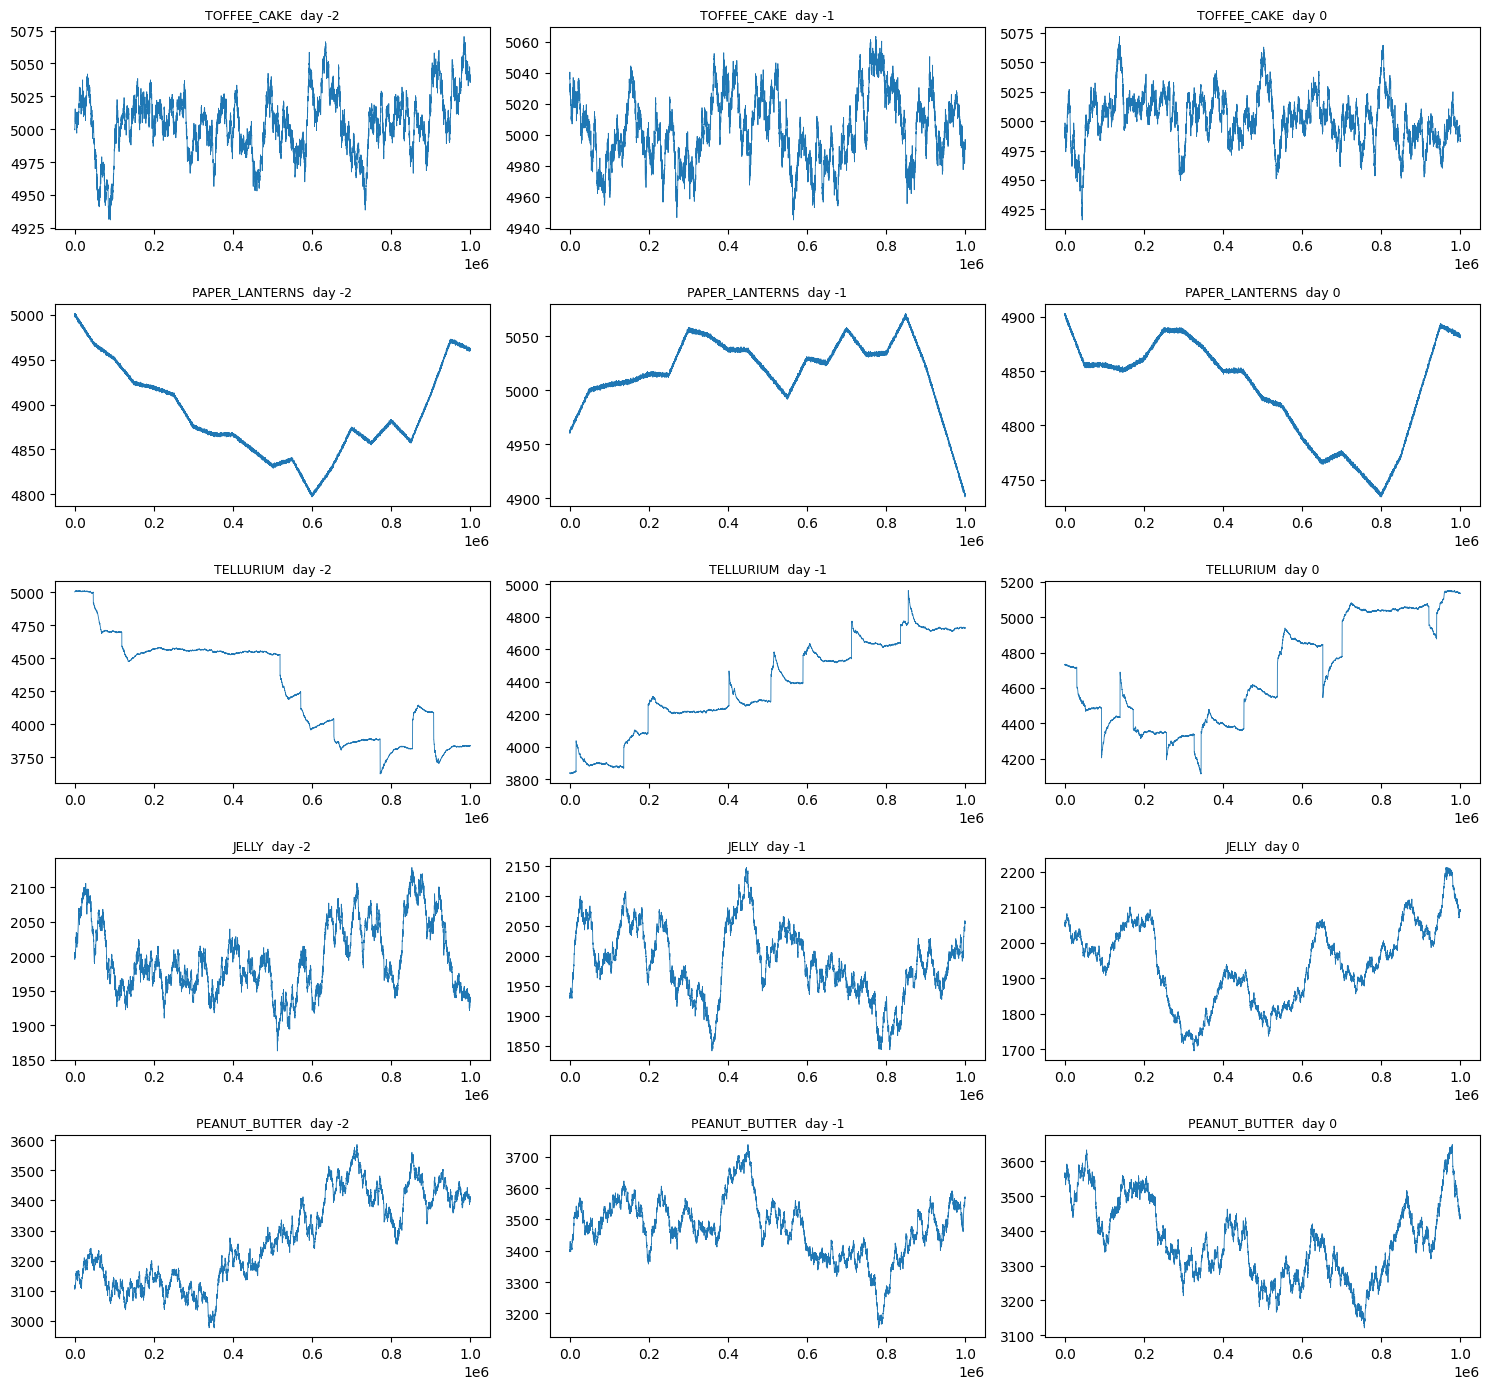

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

days = [-2, -1, 0]
df = pd.concat([pd.read_csv(f"../../data/prices_day_{d}.csv", sep=";") for d in days])

MINE = ["TOFFEE_CAKE", "PAPER_LANTERNS", "TELLURIUM", "JELLY", "PEANUT_BUTTER"]
df.head()
fig, axes = plt.subplots(len(MINE), 3, figsize=(15, 14))
for i, p in enumerate(MINE):
    for j, d in enumerate(days):
        x = df[(df["product"] == p) & (df["day"] == d)]
        axes[i, j].plot(x["timestamp"], x["mid_price"], lw=0.6)
        axes[i, j].set_title(f"{p}  day {d}", fontsize=9)
plt.tight_layout()
plt.savefig("mid_prices.png")
plt.show()

In [6]:
import numpy as np

for p in MINE:
    print(f"\n=== {p} ===")
    for d in days:
        m = df[(df["product"] == p) & (df["day"] == d)]["mid_price"].reset_index(drop=True)
        r = m.diff()

        # 1) tick bounce: negative = price zig-zags tick to tick (good for market making)
        bounce = r.autocorr(1)

        # 2) after price moves away from its average, does it come back?
        #    negative = comes back (mean reversion), positive = keeps going (trend)
        res = {}
        for w in [20, 100, 500]:
            dev = m - m.rolling(w).mean()
            future = m.shift(-50) - m
            res[w] = round(dev.corr(future), 2)

        print(f"day {d}: bounce={bounce:.2f}  reversion(w=20,100,500)={res}")


=== TOFFEE_CAKE ===
day -2: bounce=-0.23  reversion(w=20,100,500)={20: np.float64(-0.05), 100: np.float64(-0.13), 500: np.float64(-0.24)}
day -1: bounce=-0.23  reversion(w=20,100,500)={20: np.float64(-0.07), 100: np.float64(-0.14), 500: np.float64(-0.25)}
day 0: bounce=-0.23  reversion(w=20,100,500)={20: np.float64(-0.01), 100: np.float64(-0.08), 500: np.float64(-0.26)}

=== PAPER_LANTERNS ===
day -2: bounce=-0.50  reversion(w=20,100,500)={20: np.float64(0.11), 100: np.float64(0.65), 500: np.float64(0.63)}
day -1: bounce=-0.49  reversion(w=20,100,500)={20: np.float64(0.14), 100: np.float64(0.68), 500: np.float64(0.68)}
day 0: bounce=-0.50  reversion(w=20,100,500)={20: np.float64(0.08), 100: np.float64(0.65), 500: np.float64(0.7)}

=== TELLURIUM ===
day -2: bounce=-0.00  reversion(w=20,100,500)={20: np.float64(0.14), 100: np.float64(0.19), 500: np.float64(0.06)}
day -1: bounce=-0.01  reversion(w=20,100,500)={20: np.float64(-0.01), 100: np.float64(0.0), 500: np.float64(-0.09)}
day 0: bo

In [7]:
for p in MINE:
    x = df[df["product"] == p]
    spread = x["ask_price_1"] - x["bid_price_1"]
    move = x.groupby("day")["mid_price"].diff().abs()
    print(f"{p:15s} spread: median={spread.median():.0f}  10%={spread.quantile(.1):.0f}  90%={spread.quantile(.9):.0f}"
          f"   avg tick move={move.mean():.2f}")

TOFFEE_CAKE     spread: median=15  10%=13  90%=17   avg tick move=2.36
PAPER_LANTERNS  spread: median=4  10%=3  90%=5   avg tick move=1.21
TELLURIUM       spread: median=9  10%=8  90%=12   avg tick move=1.33
JELLY           spread: median=11  10%=9  90%=13   avg tick move=2.49
PEANUT_BUTTER   spread: median=6  10%=5  90%=7   avg tick move=3.82


In [8]:
tr = pd.concat([pd.read_csv(f"../../data/trades_day_{d}.csv", sep=";").assign(day=d) for d in days])
tr = tr.rename(columns={"symbol": "product"})

# attach the mid price at the moment of each trade
tr = tr.merge(df[["day", "timestamp", "product", "mid_price"]], on=["day", "timestamp", "product"], how="left")
tr["dist"] = (tr["price"] - tr["mid_price"]).abs()

for p in MINE:
    t = tr[tr["product"] == p]
    print(f"{p:15s} trades/day={len(t)/3:6.0f}  avg size={t['quantity'].mean():.1f}  "
          f"distance from mid: median={t['dist'].median():.1f}  25%={t['dist'].quantile(.25):.1f}  75%={t['dist'].quantile(.75):.1f}")

TOFFEE_CAKE     trades/day=    45  avg size=3.5  distance from mid: median=7.5  25%=7.0  75%=8.0
PAPER_LANTERNS  trades/day=   103  avg size=2.5  distance from mid: median=2.0  25%=1.5  75%=2.5
TELLURIUM       trades/day=  1225  avg size=4.0  distance from mid: median=7.0  25%=5.5  75%=8.5
JELLY           trades/day=    63  avg size=2.6  distance from mid: median=5.5  25%=5.0  75%=6.0
PEANUT_BUTTER   trades/day=    65  avg size=2.5  distance from mid: median=3.0  25%=2.5  75%=3.5


In [9]:
# 1) TELLURIUM: are trades balanced, or one-sided before moves?
t = tr[tr["product"] == "TELLURIUM"].copy()
t["signed"] = t["price"] - t["mid_price"]           # + = trade above mid (buyer), - = below (seller)
print("TELLURIUM trades above mid:", (t["signed"] > 0).mean().round(2), " below mid:", (t["signed"] < 0).mean().round(2))

# what happens to TELLURIUM's price in the 50 ticks after a trade?
m = df[df["product"] == "TELLURIUM"][["day", "timestamp", "mid_price"]].copy()
m["future"] = m.groupby("day")["mid_price"].shift(-50) - m["mid_price"]
t = t.merge(m[["day", "timestamp", "future"]], on=["day", "timestamp"])
print("avg price move after trades ABOVE mid:", t[t.signed > 0]["future"].mean().round(1))
print("avg price move after trades BELOW mid:", t[t.signed < 0]["future"].mean().round(1))

# 2) risk: biggest price moves over 100 and 1000 ticks
for p in MINE:
    x = df[df["product"] == p]
    for w in [100, 1000]:
        mv = (x.groupby("day")["mid_price"].shift(-w) - x["mid_price"]).abs()
        print(f"{p:15s} worst {w:4d}-tick move: {mv.max():6.0f}   typical(90%): {mv.quantile(.9):5.0f}")

TELLURIUM trades above mid: 0.49  below mid: 0.51
avg price move after trades ABOVE mid: 11.7
avg price move after trades BELOW mid: -5.6
TOFFEE_CAKE     worst  100-tick move:     89   typical(90%):    34
TOFFEE_CAKE     worst 1000-tick move:    135   typical(90%):    54
PAPER_LANTERNS  worst  100-tick move:     17   typical(90%):    10
PAPER_LANTERNS  worst 1000-tick move:    123   typical(90%):    64
TELLURIUM       worst  100-tick move:    381   typical(90%):   108
TELLURIUM       worst 1000-tick move:    574   typical(90%):   319
JELLY           worst  100-tick move:    148   typical(90%):    54
JELLY           worst 1000-tick move:    352   typical(90%):   162
PEANUT_BUTTER   worst  100-tick move:    169   typical(90%):    78
PEANUT_BUTTER   worst 1000-tick move:    378   typical(90%):   198
